# IND320 project work, part 3: Data quality

This notebook continues my IND320 work from the first two parts. I use NVE reservoir statistics and Open-Meteo historical weather data to explore seasonal patterns and flag unusual observations. The analysis code is kept in `utils/quality_utils.py` so the same functions can be used by the Streamlit pages.

I developed this part on `project-part-3` and merged it into `main` after receiving the Part 2 feedback. I use the same repository and Streamlit address throughout.

## Preparing the project environment

I use the local course environment for the notebook. The local requirements include the geospatial packages needed to read the NVE area shapefile.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Adding the project folder lets the notebook import the same functions as the app.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "streamlit_app.py").exists():
    PROJECT_DIR = PROJECT_DIR.parent
sys.path.insert(0, str(PROJECT_DIR))

from utils.quality_utils import (
    build_electricity_sample,
    build_weather_sample,
    fill_spectrogram,
    load_electricity_areas,
    load_nve_regions,
    load_open_meteo_region,
    lof_temperature_plot,
    spc_precipitation_plot,
    stl_decomposition,
)
from utils.data_utils import load_reservoirs

print(f"Project folder: {PROJECT_DIR.name}")

2026-11-09 16:11:27.121 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-09 16:11:27.122 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-09 16:11:27.123 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-09 16:11:27.124 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


Project folder: final-peer-review


## Reading the NVE area polygons

I use the NVE bidding-zone polygons for NO1 to NO5 and the NVE region polygons for RS, RØ, RV, RM and RN. This lets me keep the electricity areas and the regional weather sample separate. The eastern region sample uses RS and RØ, while the northern sample keeps RM and RN available as separate regions.

In [2]:
regions = load_nve_regions(PROJECT_DIR / "data" / "areas" / "nve_regions.zip")
electricity_areas = load_electricity_areas(
    PROJECT_DIR / "data" / "areas" / "electricity_areas.zip"
)

print("NVE weather regions:")
display(regions[["reg_code", "reg_name"]])
print("NVE electricity bidding zones:")
display(electricity_areas[["area_code"]])

NVE weather regions:


,reg_code,reg_name
0,RS,Region Sør
1,RØ,Region Øst
2,RV,Region Vest
3,RM,Region Midt-Norge
4,RN,Region Nord


NVE electricity bidding zones:


,area_code
0,NO1
1,NO2
2,NO3
3,NO4
4,NO5


## Sampling locations in each area

I draw 1,000 random points inside each electricity bidding zone and each NVE region polygon. Sampling is done in an equal-area projection, and fixed seeds make the coordinates repeatable. The two samples stay separate because the price zones and NVE regions have different boundaries.

In [3]:
# Fixed seeds regenerate the same coordinates without storing CSV files.
weather_points = build_weather_sample(regions, n_each=1000, seed=320)
electricity_points = build_electricity_sample(electricity_areas, n_each=1000, seed=640)

print("Weather-region sample sizes:")
display(weather_points.groupby("region_group").size().rename("locations"))
print("Electricity-area sample sizes:")
display(electricity_points.groupby("area_group").size().rename("locations"))

Weather-region sample sizes:


region_group
RM    1000
RN    1000
RS    1000
RV    1000
RØ    1000
Name: locations, dtype: int64

Electricity-area sample sizes:


area_group
NO1    1000
NO2    1000
NO3    1000
NO4    1000
NO5    1000
Name: locations, dtype: int64

## Understanding the Open-Meteo request

The Historical Weather API accepts coordinates, a start and end date, hourly variables and a weather model. I use ERA5 and request precipitation and 2 m temperature. The API does not require a token for this non-commercial use. Multiple coordinates are sent in batches so the yearly request stays within a reasonable size.

In [4]:
import requests

# This small preview shows the request structure without downloading a full year.
request = requests.Request(
    "GET",
    "https://archive-api.open-meteo.com/v1/archive",
    params={
        "latitude": "63.4,63.5",
        "longitude": "10.4,10.5",
        "start_date": "2024-01-01",
        "end_date": "2024-01-02",
        "hourly": "precipitation,temperature_2m",
        "models": "era5",
        "timezone": "Europe/Oslo",
    },
).prepare()
print(request.url)

https://archive-api.open-meteo.com/v1/archive?latitude=63.4%2C63.5&longitude=10.4%2C10.5&start_date=2024-01-01&end_date=2024-01-02&hourly=precipitation%2Ctemperature_2m&models=era5&timezone=Europe%2FOslo


## Downloading NO3 weather for 2024

I use five randomly sampled coordinates from the NO3 bidding-zone polygon for this example. The in-memory sample has 1,000 points for each electricity area, while the weather-region points are kept in a separate table. A full year for every point creates a very large API response, so I average five locations for the 2024 example. The same function can be used with another electricity area and date interval.

In [5]:
# Five locations keep the full-year hourly response small enough to rerun reliably.
weather_no3_2024 = load_open_meteo_region(
    "NO3",
    "2024-01-01",
    "2024-12-31",
    point_count=5,
    sample_points=electricity_points,
)
weather_no3_2024.head()

2026-11-09 16:11:28.557 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


,time,precipitation,temperature_2m
0,2024-01-01 00:00:00,0.02,-3.06
1,2024-01-01 01:00:00,0.02,-3.10
2,2024-01-01 02:00:00,0.00,-3.30
3,2024-01-01 03:00:00,0.00,-3.28
4,2024-01-01 04:00:00,0.00,-3.38


In [6]:
# I check the time coverage and missing values before using the hourly averages.
weather_no3_2024.agg({
    "time": ["min", "max", "count"],
    "precipitation": ["mean", "median", "count"],
    "temperature_2m": ["mean", "median", "count"],
})

,time,precipitation,temperature_2m
min,2024-01-01 00:00:00,NaN,NaN
max,2024-12-31 23:00:00,NaN,NaN
count,8784,8784.000000,8784.000000
mean,NaN,0.253841,5.173889
median,NaN,0.100000,4.960000


## Checking precipitation outliers with SPC

I use a DCT high-pass filter to form SATV, then estimate robust control limits from the full-year data. SATV is only used for detection, so the plot stays on the precipitation scale. I add the DCT background back to the residual limits at every hour; the displayed curves therefore match the outlier decision exactly. Negative lower limits are statistical boundaries, not predictions of negative rainfall.

{'observations': 8784,
 'outliers': 959,
 'outlier_percent': 10.917577413479053,
 'residual_median_mm': -0.0035373208350731634,
 'residual_robust_sd_mm': 0.0686792785736274,
 'residual_lower_limit_mm': -0.20957515655595538,
 'residual_upper_limit_mm': 0.20250051488580906,
 'dct_cutoff_fraction': 0.08,
 'robust_sd_multiplier': 3.0}

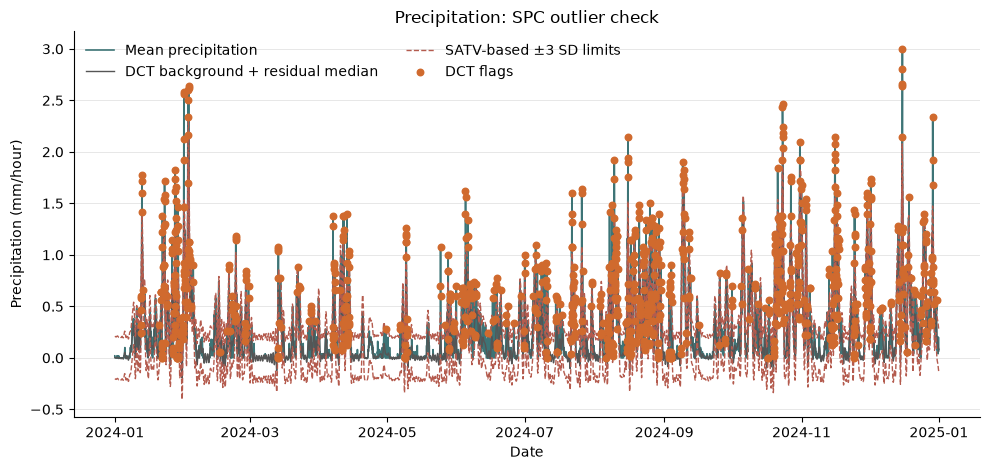

In [7]:
# These settings are visible because changing the cutoff or limit changes which hours are flagged.
spc_figure, spc_summary = spc_precipitation_plot(
    weather_no3_2024,
    cutoff=0.08,
    n_sd=3.0,
)
display(spc_summary)
# Display the figure explicitly so the PDF includes the analysis.
plt.show()


The highlighted hours differ from the DCT-based background. A flag is a prompt for investigation, not evidence of a measurement error; heavy rain can be a real event.

## Finding temperature anomalies with LOF

The temperature series has a seasonal cycle, so the LOF function also includes each hour's difference from a rolling 24-hour median. I use a default anomaly proportion of 1%, which can be changed when I compare results.

{'observations': 8784,
 'anomalies': 88,
 'anomaly_percent': 1.0018214936247722,
 'contamination': 0.01,
 'median_temperature_c': 4.96}

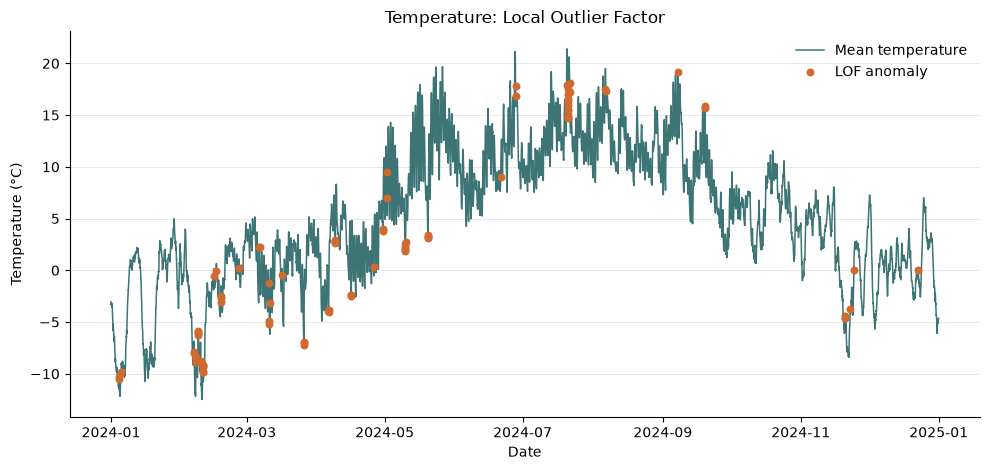

In [8]:
lof_figure, lof_summary = lof_temperature_plot(
    weather_no3_2024,
    contamination=0.01,
)
display(lof_summary)
# Display the figure explicitly so the PDF includes the analysis.
plt.show()


The temperature curve shows the annual cycle. The 1% LOF setting controls the proportion marked, so the number of anomalies also reflects my chosen setting.

## Reading the NVE reservoir series

The reservoir data is weekly, while the weather data is hourly. I keep the series at its original time resolution rather than joining hourly values to weekly reservoir observations. For the pattern analysis I select the NVE electricity area NO3.

In [9]:
reservoirs = load_reservoirs()
reservoir_no3 = reservoirs.loc[
    (reservoirs["area_type"] == "EL") & (reservoirs["area_number"] == 3)
].sort_values("date")
fill_no3 = reservoir_no3.set_index("date")["fill_fraction"].mul(100)

print(f"NO3 contains {len(fill_no3):,} weekly observations.")
reservoir_no3[["date", "fill_fraction", "capacity_twh", "stored_energy_twh"]].tail()

2026-11-09 16:11:31.109 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-09 16:11:31.109 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


NO3 contains 1,661 weekly observations.


,date,fill_fraction,capacity_twh,stored_energy_twh
14906,2026-10-04,0.718754,8.920932,6.411958
14915,2026-10-11,0.725240,8.920932,6.469815
14924,2026-10-18,0.724940,8.920932,6.467144
14933,2026-10-25,0.717647,8.920932,6.402080
14942,2026-11-01,0.720149,8.920932,6.424399


## Separating the seasonal pattern with STL

A period of 52 represents a year in a weekly series. STL returns the observed values, trend, seasonal component and residuals. I keep robust fitting on by default because a few unusual weeks should have less influence on the smooth components.

,observed,trend,seasonal,residual
date,,,,
2026-10-04,71.875423,44.051231,23.831858,3.992334
2026-10-11,72.523980,43.581277,26.045048,2.897655
2026-10-18,72.494050,43.111877,26.605613,2.776560
2026-10-25,71.764696,42.643051,26.338816,2.782829
2026-11-01,72.014890,42.174810,25.887280,3.952800


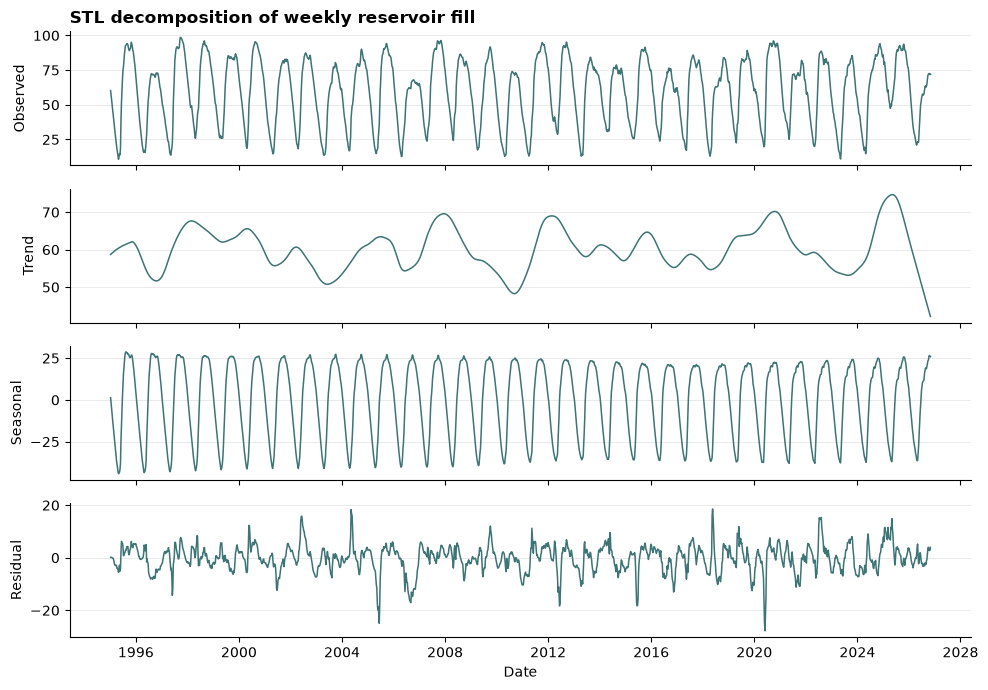

In [10]:
stl_figure, stl_components = stl_decomposition(
    fill_no3,
    period=52,
    seasonal_smoother=13,
    trend_smoother=None,
    robust=True,
)
display(stl_components.tail())
# Display the figure explicitly so the PDF includes the analysis.
plt.show()


The seasonal component shows the repeating yearly reservoir cycle. The trend describes slower changes, while the residual shows variation not captured by those two components.

## Viewing frequency changes with a spectrogram

The spectrogram uses the same weekly series. Window length controls how much data is used in each frequency estimate, and overlap controls how often a new estimate is made. More overlap gives a smoother view over time, but it does not add new observations.

{'observations': 1661,
 'window_weeks': 104,
 'overlap_weeks': 78,
 'time_windows': 60}

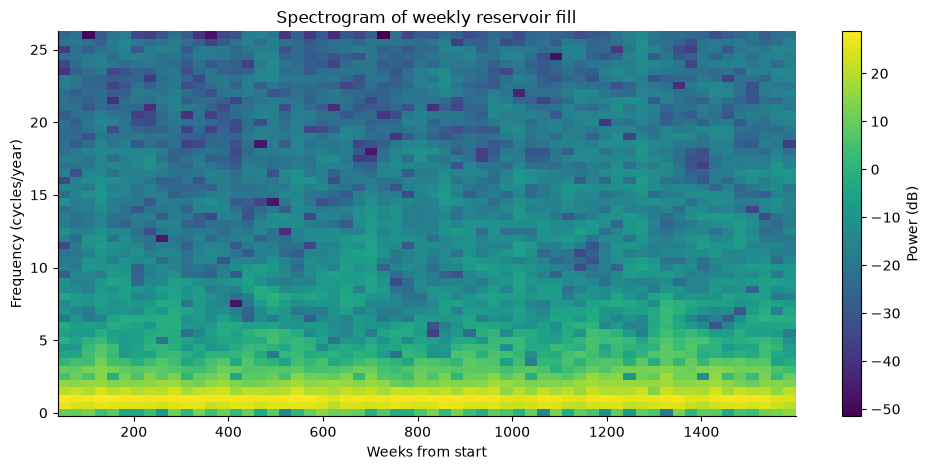

In [11]:
spectrum_figure, spectrum_summary = fill_spectrogram(
    fill_no3,
    window_weeks=104,
    overlap_weeks=78,
)
display(spectrum_summary)
# Display the figure explicitly so the PDF includes the analysis.
plt.show()


Brighter colours indicate stronger repeating patterns. The low-frequency band shows slow and seasonal variation; changing the window trades time detail for frequency detail.

## Adding the analyses to Streamlit

The app has a reservoir-pattern page with tabs for STL and the spectrogram, and a weather-outlier page with tabs for SPC and LOF. A shared sidebar electricity-area selector controls both the reservoir-pattern analysis and the weather download. The weather function uses coordinates sampled inside the matching NO1–NO5 polygon. I keep the separate NVE region sample for describing the regional boundaries, including the RS+RØ east and RM+RN north groups.

## AI use

I used AI to get a starting structure and initial code examples, which I then worked on and adapted for my project. I also used AI as learning support to understand API parameters and analysis methods, and for troubleshooting. I organised the GitHub repository myself to get a clearer overview, with AI support for the structure. I wrote the code comments myself. AI also helped with checks and exporting the notebook. I remain responsible for understanding and checking the submitted work.

## Work log

In this part I extended the reservoir app with weather data and a few methods for checking patterns and unusual observations. I started by downloading the NVE electricity bidding-zone polygons and NVE region polygons. I made a fixed random sample of 1,000 coordinates in each electricity area and each NVE region. The samples are generated in memory instead of saved as CSV files. Fixed seeds make them repeatable, and keeping the two sets separate matters because the boundaries describe different things.

I used Open-Meteo's Historical Weather API to retrieve hourly ERA5 precipitation and temperature. For the NO3 example, I selected five locations from inside the NO3 bidding-zone polygon for 2024 and averaged their hourly values. I first tried a much larger request, which was slow and hit the API's hourly request limit. I changed the code to request data month by month and use a smaller location sample. The app then loaded 8,784 hourly observations for 2024, including for NO3. The weather data still come from Open-Meteo; the smaller sample is a practical choice for making the request manageable.

For precipitation, I use a DCT high-pass filter to create the SATV signal and use it only to decide which hours to flag. The plot stays on the original precipitation scale, with robust limits estimated from the median and MAD. I also use Local Outlier Factor on temperature, using both the temperature and its difference from a 24-hour rolling median. I left the cutoff and anomaly settings visible because changing them affects which observations are marked.

I use STL to separate the weekly reservoir series into trend, seasonal and residual components. The spectrogram gives another view of repeating patterns, with window length and overlap available as settings. I kept these methods in separate functions so I can reuse them with another series and see how the settings change the result.

I added two pages to the existing Streamlit app. Reservoir patterns has tabs for STL and the spectrogram, while Weather outliers has tabs for precipitation checks and temperature anomalies. I also added an area selector so the weather sample is drawn from the matching electricity-zone polygon. The page reports how many hourly observations were loaded, and the app splits API requests by month so the selected date range can be handled in smaller pieces. I checked the new plots with the NVE reservoir series and with hourly weather data. I developed the changes on project-part-3 and merged them into main after the Part 2 feedback. I organised the GitHub repository myself, grouping notebooks, PDFs and recordings into separate folders to make the work easier to find. AI provided a starting structure and initial code examples that I worked on and adapted, and helped with explanations and troubleshooting, as described in the AI use section. I wrote the code comments myself, including the comments on the Streamlit pages, following the feedback from Part 2.

## Project links

GitHub repository: https://github.com/Sivan00/IND320-Sivan00-Project1

Streamlit app: https://ind320-sivan00-project1.streamlit.app/

Part 3 was developed on `project-part-3` and merged into `main` after the Part 2 feedback.

## Screencast

[Watch or download the Project 3 screencast](https://github.com/Sivan00/IND320-Sivan00-Project1/releases/download/project-3/IND320_project_3_screencast.mp4) ([release page](https://github.com/Sivan00/IND320-Sivan00-Project1/releases/tag/project-3)). The recording shows all seven Streamlit pages followed by the notebook. Duration: 5 minutes 43 seconds.